<a href="https://colab.research.google.com/github/poohkap10/DSP-Labs/blob/main/mini_project2294%2C2227%2C2261.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q librosa soundfile scipy

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display
import soundfile as sf

from scipy import signal
from IPython.display import Audio, display
from google.colab import files

In [ ]:
uploaded = files.upload()

filename = list(uploaded.keys())[0]

y, sr = librosa.load(filename, sr=None, mono=True)

print("File:", filename)
print("Sample Rate:", sr, "Hz")
print("Duration:", round(len(y) / sr, 2), "seconds")

Saving Recording.wav to Recording.wav


/tmp/ipykernel_2328/632721042.py:5: UserWarning: PySoundFile failed. Trying audioread instead.
  y, sr = librosa.load(filename, sr=None, mono=True)
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


File: Recording.wav
Sample Rate: 96000 Hz
Duration: 8.75 seconds


In [ ]:
print("🎙️ Original Voice")

display(Audio(y, rate=sr))

🎙️ Original Voice


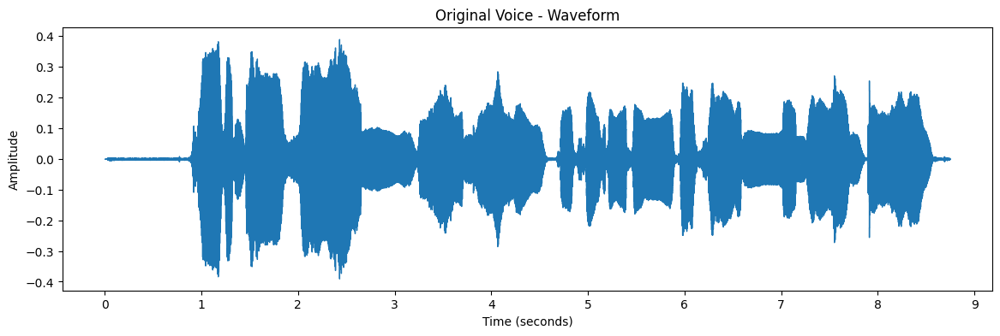

In [ ]:
plt.figure(figsize=(14, 4))

librosa.display.waveshow(y, sr=sr)

plt.title("Original Voice - Waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

plt.show()

In [ ]:
def plot_fft(y, sr, title):

    n = len(y)

    fft_result = np.fft.rfft(y)

    magnitude = np.abs(fft_result) / n

    frequencies = np.fft.rfftfreq(
        n,
        1 / sr
    )

    plt.figure(figsize=(14, 4))

    plt.plot(
        frequencies,
        magnitude
    )

    plt.title(title)
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Magnitude")

    plt.xlim(0, 5000)

    plt.grid()

    plt.show()

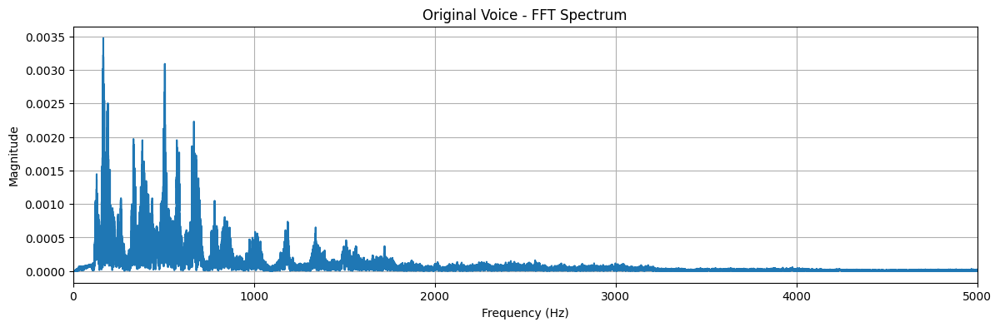

In [ ]:
plot_fft(
    y,
    sr,
    "Original Voice - FFT Spectrum"
)

In [ ]:
voice_high = librosa.effects.pitch_shift(
    y=y,
    sr=sr,
    n_steps=4
)

print("🔊 เสียงสูง")

display(
    Audio(
        voice_high,
        rate=sr
    )
)

🔊 เสียงสูง


In [ ]:
voice_low = librosa.effects.pitch_shift(
    y=y,
    sr=sr,
    n_steps=-4
)

print("🔊 เสียงต่ำ")

display(
    Audio(
        voice_low,
        rate=sr
    )
)

🔊 เสียงต่ำ


In [ ]:
def robot_voice(
    y,
    sr,
    carrier_freq=80
):

    t = np.arange(
        len(y)
    ) / sr

    carrier = np.sin(
        2 * np.pi *
        carrier_freq *
        t
    )

    robot = y * carrier

    return robot

In [ ]:
voice_robot = robot_voice(
    y,
    sr,
    carrier_freq=80
)

print("🤖 เสียงหุ่นยนต์")

display(
    Audio(
        voice_robot,
        rate=sr
    )
)

🤖 เสียงหุ่นยนต์


In [ ]:
def radio_voice(y, sr):

    lowcut = 300
    highcut = 3400

    sos = signal.butter(
        6,
        [lowcut, highcut],
        btype="bandpass",
        fs=sr,
        output="sos"
    )

    filtered = signal.sosfilt(
        sos,
        y
    )

    filtered = filtered / (
        np.max(
            np.abs(filtered)
        ) + 1e-9
    )

    return filtered

In [ ]:
voice_radio = radio_voice(
    y,
    sr
)

print("📻 เสียงวิทยุ")

display(
    Audio(
        voice_radio,
        rate=sr
    )
)

📻 เสียงวิทยุ


In [ ]:
print("🎙️ ORIGINAL")
display(Audio(y, rate=sr))

print("🔊 HIGH VOICE")
display(Audio(voice_high, rate=sr))

print("🔊 LOW VOICE")
display(Audio(voice_low, rate=sr))

print("🤖 ROBOT VOICE")
display(Audio(voice_robot, rate=sr))

print("📻 RADIO VOICE")
display(Audio(voice_radio, rate=sr))

🎙️ ORIGINAL


🔊 HIGH VOICE


🔊 LOW VOICE


🤖 ROBOT VOICE


📻 RADIO VOICE


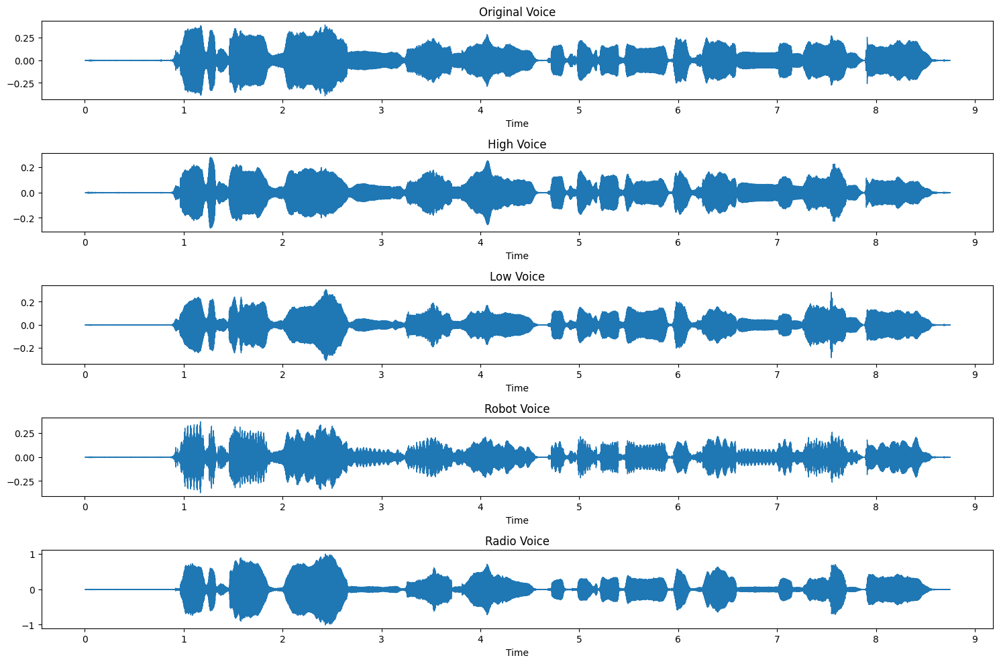

In [ ]:
plt.figure(figsize=(15, 10))

plt.subplot(5, 1, 1)
librosa.display.waveshow(y, sr=sr)
plt.title("Original Voice")

plt.subplot(5, 1, 2)
librosa.display.waveshow(voice_high, sr=sr)
plt.title("High Voice")

plt.subplot(5, 1, 3)
librosa.display.waveshow(voice_low, sr=sr)
plt.title("Low Voice")

plt.subplot(5, 1, 4)
librosa.display.waveshow(voice_robot, sr=sr)
plt.title("Robot Voice")

plt.subplot(5, 1, 5)
librosa.display.waveshow(voice_radio, sr=sr)
plt.title("Radio Voice")

plt.tight_layout()

plt.show()

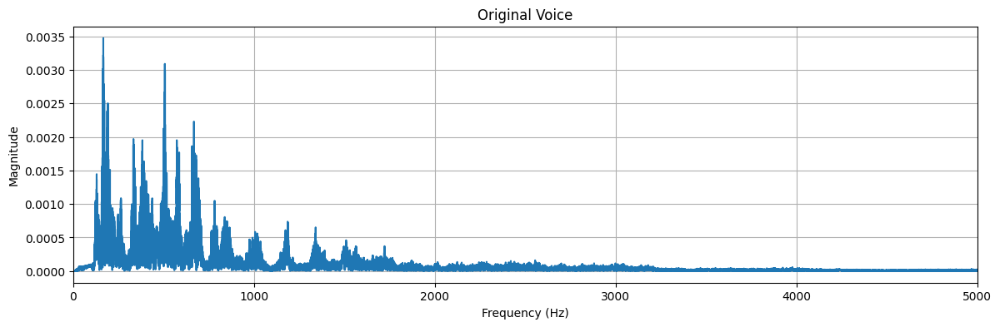

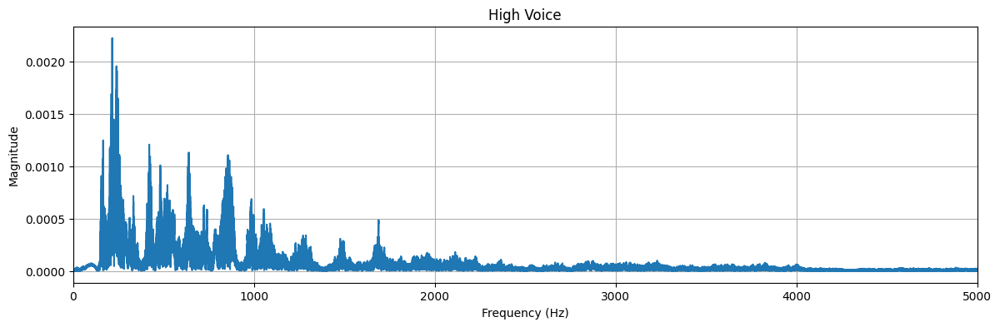

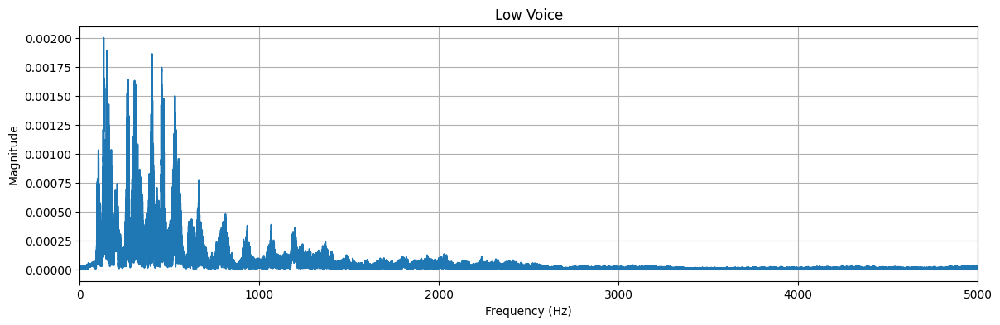

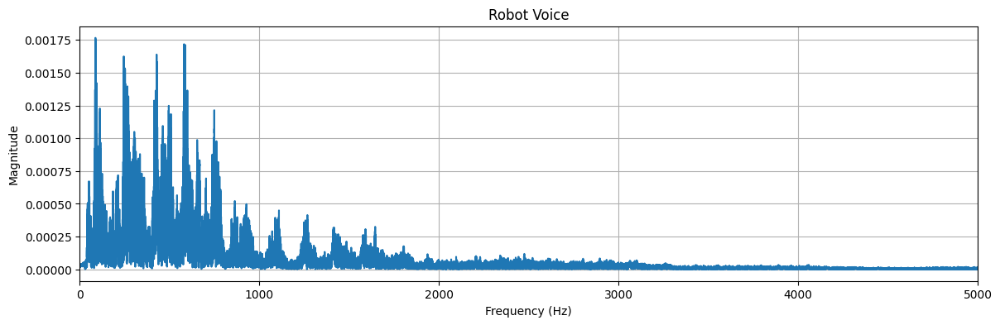

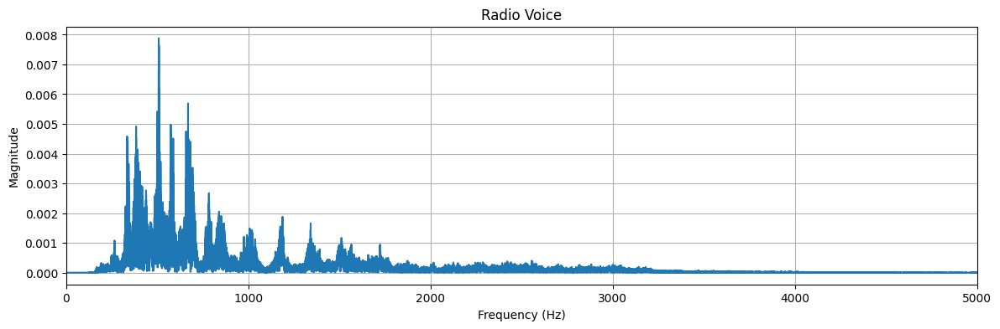

In [ ]:
plot_fft(
    y,
    sr,
    "Original Voice"
)

plot_fft(
    voice_high,
    sr,
    "High Voice"
)

plot_fft(
    voice_low,
    sr,
    "Low Voice"
)

plot_fft(
    voice_robot,
    sr,
    "Robot Voice"
)

plot_fft(
    voice_radio,
    sr,
    "Radio Voice"
)

In [ ]:
sf.write(
    "high_voice.wav",
    voice_high,
    sr
)

sf.write(
    "low_voice.wav",
    voice_low,
    sr
)

sf.write(
    "robot_voice.wav",
    voice_robot,
    sr
)

sf.write(
    "radio_voice.wav",
    voice_radio,
    sr
)

print("บันทึกไฟล์เรียบร้อยแล้ว")

บันทึกไฟล์เรียบร้อยแล้ว


In [ ]:
files.download(
    "robot_voice.wav"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>